In [3]:
data = createDataSet()
data

([[0, 0, 0, 0, 'no'],
  [0, 0, 0, 1, 'no'],
  [0, 1, 0, 1, 'yes'],
  [0, 1, 1, 0, 'yes'],
  [0, 0, 0, 0, 'no'],
  [1, 0, 0, 0, 'no'],
  [1, 0, 0, 1, 'no'],
  [1, 1, 1, 1, 'yes'],
  [1, 0, 1, 2, 'yes'],
  [1, 0, 1, 2, 'yes'],
  [2, 0, 1, 2, 'yes'],
  [2, 0, 1, 1, 'yes'],
  [2, 1, 0, 1, 'yes'],
  [2, 1, 0, 2, 'yes'],
  [2, 0, 0, 0, 'no']],
 ['年龄', '有工作', '有自己的房子', '信贷情况'])

In [4]:
calcShannonEnt(data[0])
splitDataSet(data[0],3,0)
chooseBestFeatureToSplit(data[0])

2

In [10]:
data[0]

[[0, 0, 0, 0, 'no'],
 [0, 0, 0, 1, 'no'],
 [0, 1, 0, 1, 'yes'],
 [0, 1, 1, 0, 'yes'],
 [0, 0, 0, 0, 'no'],
 [1, 0, 0, 0, 'no'],
 [1, 0, 0, 1, 'no'],
 [1, 1, 1, 1, 'yes'],
 [1, 0, 1, 2, 'yes'],
 [1, 0, 1, 2, 'yes'],
 [2, 0, 1, 2, 'yes'],
 [2, 0, 1, 1, 'yes'],
 [2, 1, 0, 1, 'yes'],
 [2, 1, 0, 2, 'yes'],
 [2, 0, 0, 0, 'no']]

In [12]:
classList = [example[-1] for example in data[0]]
majorityCnt(classList)

'yes'

In [13]:
classList



['no',
 'no',
 'yes',
 'yes',
 'no',
 'no',
 'no',
 'yes',
 'yes',
 'yes',
 'yes',
 'yes',
 'yes',
 'yes',
 'no']

In [11]:
from math import log
import operator
import pickle
import numpy as np

# 创建数据集
def createDataSet():
    dataSet = [[0, 0, 0, 0, 'no'],                        #数据集
            [0, 0, 0, 1, 'no'],
            [0, 1, 0, 1, 'yes'],
            [0, 1, 1, 0, 'yes'],
            [0, 0, 0, 0, 'no'],
            [1, 0, 0, 0, 'no'],
            [1, 0, 0, 1, 'no'],
            [1, 1, 1, 1, 'yes'],
            [1, 0, 1, 2, 'yes'],
            [1, 0, 1, 2, 'yes'],
            [2, 0, 1, 2, 'yes'],
            [2, 0, 1, 1, 'yes'],
            [2, 1, 0, 1, 'yes'],
            [2, 1, 0, 2, 'yes'],
            [2, 0, 0, 0, 'no']]
    labels = ['年龄', '有工作', '有自己的房子', '信贷情况']        #特征标签
    return dataSet, labels                             #返回数据集和分类属性


#计算经验熵(香农熵)。最后一列对应的熵
def calcShannonEnt(dataSet):
    #返回数据集的行数
    numEntires = len(dataSet)       
    
    #收集所有目标标签 （最后一个维度）
    labels= [featVec[-1] for featVec in dataSet]     
    # 去重、获取标签种类
    keys = set(labels)

    shannonEnt = 0.0
    for key in keys:
       # print(key)
       # 计算每种标签出现的次数
       prob = float(labels.count(key)) / numEntires 
       # print(prob)
       shannonEnt -= prob * log(prob, 2) 
    return shannonEnt
    
# 数据集分割
# 将第axis列等于 value 的数据集提取出来，而且不要第axis列的数据
def splitDataSet(dataSet, axis, value):        
    retDataSet = []                                        #创建返回的数据集列表
    for featVec in dataSet:                             #遍历数据集
        if featVec[axis] == value:
            reducedFeatVec = featVec[:axis]                #去掉axis特征
            reducedFeatVec.extend(featVec[axis+1:])     #将符合条件的添加到返回的数据集
            retDataSet.append(reducedFeatVec)
    return retDataSet                                      #返回划分后的数据集


#选择最优的特征进行分类
def chooseBestFeatureToSplit(dataSet):
    numFeatures = len(dataSet[0]) - 1                    #特征数量
    baseEntropy = calcShannonEnt(dataSet)                 #计算数据集的香农熵
    bestInfoGain = 0.0                                  #信息增益
    bestFeature = -1                                    #最优特征的索引值
    for i in range(numFeatures):                         #遍历所有特征
        #获取dataSet的第i个所有特征
        featList = [example[i] for example in dataSet]  #第i列数据
        uniqueVals = set(featList)                         #创建set集合{},元素不可重复
        newEntropy = 0.0                                  #经验条件熵
        for value in uniqueVals:                         #计算信息增益
            subDataSet = splitDataSet(dataSet, i, value)         #subDataSet划分后的子集
            prob = len(subDataSet) / float(len(dataSet))           #计算子集的概率
            newEntropy += prob * calcShannonEnt(subDataSet)     #根据公式计算经验条件熵
        infoGain = baseEntropy - newEntropy                     #信息增益
        # print("第%d个特征的增益为%.3f" % (i, infoGain))            #打印每个特征的信息增益
        if (infoGain > bestInfoGain):                             #计算信息增益
            bestInfoGain = infoGain                             #更新信息增益，找到最大的信息增益
            bestFeature = i                                     #记录信息增益最大的特征的索引值
    return bestFeature                                             #返回信息增益最大的特征的索引值


#返回classList中出现次数最多的元素，这个函数有点问题：classLabel没有出现过
def majorityCnt(classList):
    classCount = {}
    keys = set(classList) #classLabel
    for key in keys:
        classCount[key] = classList.count(key)
    
    #根据字典的值降序排序
    sortedClassCount = sorted(classCount.items(), 
                              key = operator.itemgetter(1), 
                              reverse = True)  
    return sortedClassCount[0][0]   


# 创建决策树
def createTree(dataSet,labels, lab_sel):
    #取分类标签(是否放贷:yes or no)
    classList = [example[-1] for example in dataSet]
    
    #如果类别完全相同则停止继续划分
    if classList.count(classList[0]) == len(classList):           
        return classList[0]
    
    #遍历完所有特征时返回出现次数最多的类标签
    if len(dataSet[0]) == 1 or len(labels) == 0:                
        return majorityCnt(classList)
        
    #获取最优特征的维度    
    bestFeat = chooseBestFeatureToSplit(dataSet)                
    
    #得到最优特征的标签
    bestFeatLabel = labels[bestFeat]                           
    lab_sel.append(labels[bestFeat])
    
    #根据最优特征的标签生成树
    myTree = {bestFeatLabel:{}} 
    
    #删除已经使用特征标签
    del(labels[bestFeat])

    #得到训练集中所有最优特征维度的所有属性值
    featValues = [example[bestFeat] for example in dataSet]       
    uniqueVals = set(featValues)                                #去掉重复的属性值
    for value in uniqueVals:                                    #遍历特征，创建决策树。
        subLabels = labels[:]
        myTree[bestFeatLabel][value] = createTree(splitDataSet(dataSet, bestFeat, value), subLabels,lab_sel)
        
    return myTree

# 进行分类
def classify(inputTree, featLabels, testVec):
    firstStr = next(iter(inputTree))      #获取决策树结点
    secondDict = inputTree[firstStr]      #下一个字典
    featIndex = featLabels.index(firstStr)                                                
    for key in secondDict.keys():
        if testVec[featIndex] == key:
            if type(secondDict[key]).__name__ == 'dict':
                classLabel = classify(secondDict[key], featLabels, testVec)
            else: classLabel = secondDict[key]
    return classLabel

In [15]:

if __name__ == '__main__':
    
    ''' 实验一 自定义贷款数据集  '''
    # 获取数据集
    dataSet, labels = createDataSet()
    lab_copy = labels[:]
    lab_sel = []
    myTree = createTree(dataSet, labels,lab_sel)
    print(myTree)
    print(lab_sel)
    # 测试
    testVec = [0,1,1,2] 
    result = classify(myTree,lab_copy,testVec)
    print(result)
    
    
    ''' 实验二  隐形眼睛数据集 '''
    # with open("train-lenses.txt",'r',encoding='utf-8') as f:
        # lines = f.read().splitlines()
    
    # dataSet = [line.split('\t') for line in lines]
    # labels = ['年龄','近视/远视','是否散光','是否眼干']
    
    # lab_copy = labels[:]
    # lab_sel = []
    # myTree = createTree(dataSet, labels,lab_sel)
    # print(myTree)
    # print(lab_sel)
    
    # # 测试
    # with open("test-lenses.txt",'r',encoding='utf-8') as f:
        # lines = f.read().splitlines()
        
    # for line in lines:
        # data = line.split('\t')
        # lab_true = data[-1]
        # test_vec = data[:-1]
        # result = classify(myTree,lab_copy,test_vec)
        
        # print("输入特征：")
        # print(test_vec)
        # print("预测结果 %s  医生推荐 %s"%(result,lab_true))

{'有自己的房子': {0: {'有工作': {0: 'no', 1: 'yes'}}, 1: 'yes'}}
['有自己的房子', '有工作']
yes


In [18]:
data

{'data': array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
         1.065e+03],
        [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
         1.050e+03],
        [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
         1.185e+03],
        ...,
        [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
         8.350e+02],
        [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
         8.400e+02],
        [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
         5.600e+02]]),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

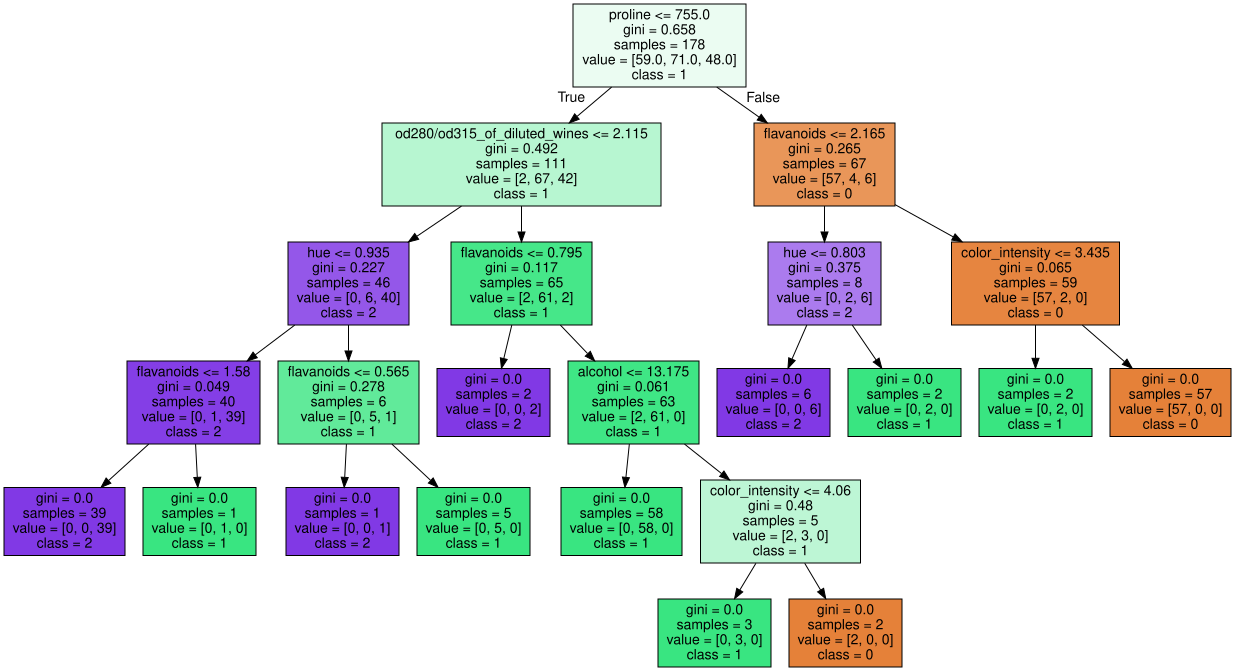

In [17]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn import tree
from sklearn.datasets import load_wine
from IPython.display import SVG
from graphviz import Source
from IPython.display import display
# load dataset
data = load_wine()

# feature matrix
X = data.data

# target vector
y = data.target

# class labels
labels = data.feature_names

# print dataset description
print(data.DESCR)
estimator = DecisionTreeClassifier()
estimator.fit(X, y)

graph = Source(tree.export_graphviz(estimator, out_file=None
   , feature_names=labels, class_names=['0', '1', '2'] 
   , filled = True))
display(SVG(graph.pipe(format='svg')))